In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib
from matplotlib import pyplot as plt
from scipy.fft import fft, fftfreq
from scipy import signal
import aotools
import matplotlib.ticker as mtick
from matplotlib.ticker import MultipleLocator, FuncFormatter, AutoMinorLocator
%matplotlib qt

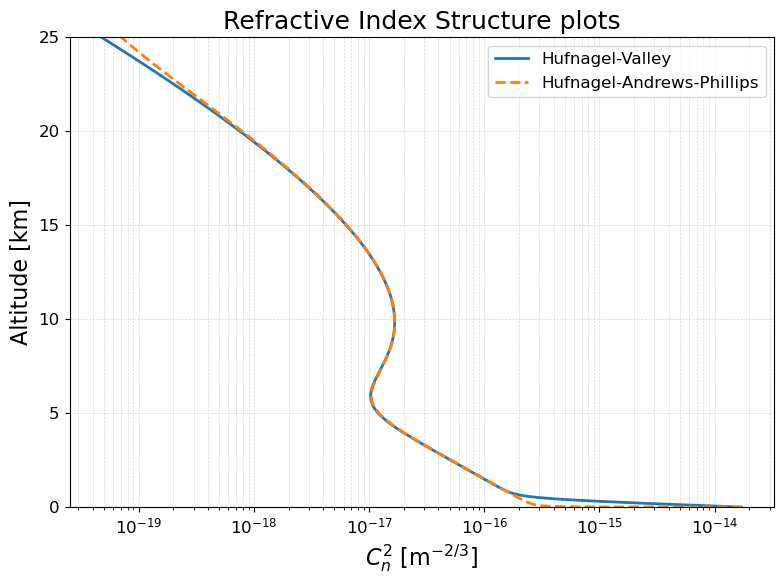

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Match thesis plot formatting
plt.rcParams.update({'font.size': 12})
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=16)

# Parameters
W = 21.0                 # RMS wind speed [m/s]
A = 1.7e-14              # Ground-level Cn^2 [m^(-2/3)]
h0 = 1.0                 # Reference height for HAP model [m]

# Altitude range
h = np.linspace(1, 25000, 4000)   # altitude [m]

# Hufnagel-Valley (HV 5/7) model
Cn2_HV = (
    0.00594 * (W / 27.0)**2 * (1e-5 * h)**10 * np.exp(-h / 1000.0)
    + 2.7e-16 * np.exp(-h / 1500.0)
    + A * np.exp(-h / 100.0)
)

# Hufnagel-Andrews-Phillips (HAP) model
Cn2_HAP = (
    0.00594 * (W / 27.0)**2 * (1e-5 * h)**10 * np.exp(-h / 1000.0)
    + 2.7e-16 * np.exp(-h / 1500.0)
    + A * (h0 / h)**(4.0 / 3.0)
)

# Convert altitude to km for plotting
h_km = h / 1000.0

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    Cn2_HV,
    h_km,
    linewidth=2,
    label="Hufnagel-Valley"
)

plt.plot(
    Cn2_HAP,
    h_km,
    linewidth=2,
    linestyle="--",
    label="Hufnagel-Andrews-Phillips"
)

plt.xscale("log")

plt.xlabel(r"$C_n^2$ [m$^{-2/3}$]")
plt.ylabel("Altitude [km]")
plt.title(r"Refractive Index Structure plots")

plt.ylim(0, 25)

plt.grid(
    True,
    which="both",
    linestyle="--",
    linewidth=0.5,
    alpha=0.5
)

plt.legend()

plt.tight_layout()
plt.savefig('C2_HV_HAP_comparison.pdf', dpi=300, bbox_inches='tight')

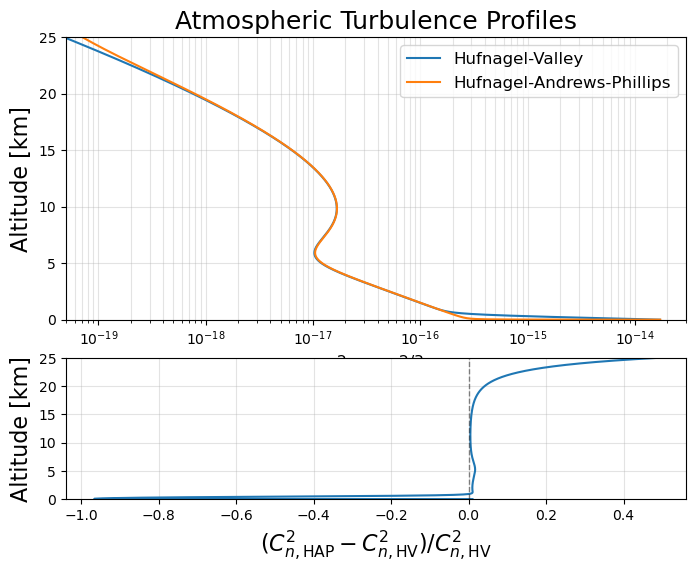

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Match formatting of your example
plt.rcParams.update({'font.size': 10})
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=16)

# Parameters
W = 21.0                 # RMS wind speed [m/s]
A = 1.7e-14              # Ground-level Cn^2 [m^(-2/3)]
h0 = 1.0                 # Reference height for HAP model [m]

# Altitude range
h = np.linspace(1, 25000, 4000)   # altitude [m]
h_km = h / 1000.0                 # altitude [km]

# Hufnagel-Valley (HV 5/7) model
Cn2_HV = (
    0.00594 * (W / 27.0)**2 * (1e-5 * h)**10 * np.exp(-h / 1000.0)
    + 2.7e-16 * np.exp(-h / 1500.0)
    + A * np.exp(-h / 100.0)
)

# Hufnagel-Andrews-Phillips (HAP) model
Cn2_HAP = (
    0.00594 * (W / 27.0)**2 * (1e-5 * h)**10 * np.exp(-h / 1000.0)
    + 2.7e-16 * np.exp(-h / 1500.0)
    + A * (h0 / h)**(4.0 / 3.0)
)

# Relative difference
rel_diff = (Cn2_HAP - Cn2_HV) / Cn2_HV

# If you want absolute difference instead, use:
# rel_diff = Cn2_HAP - Cn2_HV

# Create figure
fig, ax = plt.subplots(
    2, 1,
    gridspec_kw={'height_ratios': [2, 1]},
    sharey=True
)

fig.set_size_inches(8, 6)

# --- Top panel: main profiles ---
ax[0].semilogx(Cn2_HV, h_km, label='Hufnagel-Valley', linewidth=1.5)
ax[0].semilogx(Cn2_HAP, h_km, label='Hufnagel-Andrews-Phillips', linewidth=1.5)

ax[0].set_ylabel('Altitude [km]')
ax[0].set_xlabel(r'$C_n^2$ [$m^{-2/3}$]')
ax[0].set_title('Atmospheric Turbulence Profiles')
ax[0].legend(loc='upper right', fontsize=12, frameon=True)
ax[0].grid(True, which='both', alpha=0.35)
ax[0].set_xlim(5e-20, 3e-14)
ax[0].set_ylim(0, 25)

# --- Bottom panel: residual / relative difference ---
ax[1].plot(rel_diff, h_km, linewidth=1.5)
ax[1].axvline(0, linestyle='--', color='k', alpha=0.45, linewidth=1)

ax[1].set_xlabel(r'$(C_{n,\mathrm{HAP}}^2 - C_{n,\mathrm{HV}}^2)/C_{n,\mathrm{HV}}^2$')
ax[1].set_ylabel('Altitude [km]')
ax[1].grid(True, which='both', alpha=0.35)
ax[1].set_ylim(0, 25)

plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=None, hspace=0.18)

# Save if needed
# plt.savefig('HV_HAP_comparison_with_residual.pdf', dpi=300, bbox_inches='tight')

plt.show()